# 5. Frequency Domain

## Objetivo y recorrido

Comparar el filtrado Ideal, Butterworth y Gaussiano en el dominio de Fourier. Primero se estudian los espectros y las máscaras; después se aplican a dos problemas: reducir ruido y realzar detalles.

## Table of Contents
1. [Libraries](#libraries)
2. [Imagen de trabajo](#imagen)
3. [Fast Fourier Transform (FFT)](#fft)
4. [Low Pass Filter](#low)
5. [High Pass Filter](#high)
6. [Reducción de ruido y PSNR](#reduccion-ruido)
7. [Realce pasa-altas](#realce)
8. [Conclusión y limitaciones](#conclusion)

**Uso:** ejecutar de arriba abajo en un entorno con Python, NumPy, Matplotlib, OpenCV y scikit-image. La imagen procede de `skimage.data.camera()`; esta versión no utiliza un archivo local de imagen. Las salidas guardadas permiten revisar la práctica sin ejecutarla. Los números de ejecución no son consecutivos y no sustituyen este orden de dependencias.

**Evidencia:** las figuras 1–17 se corresponden con las salidas incluidas en [el reporte](reporte_filtrado_fourier.md). Se exportaron las imágenes ya guardadas, sin generar una corrida nueva.


## Importing Libraries <a class="anchor" id="libraries"></a>

NumPy calcula las transformadas y opera con matrices; Matplotlib muestra imágenes y espectros. Las funciones matemáticas se usan al construir máscaras. OpenCV está importado, pero la carga de imagen de esta versión corresponde a scikit-image, importado en la siguiente etapa.


In [7]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from math import sqrt,exp

## Imagen de trabajo <a class="anchor" id="imagen"></a>

Se utiliza `skimage.data.camera()`, una imagen estándar de 512 × 512 píxeles, en escala de grises y tipo `uint8`. Sus zonas suaves, texturas y bordes permiten observar distintos efectos del filtrado.

Para la aplicación pasa-bajas se añade ruido normal de media 0 y desviación estándar 18. La semilla 42 permite repetir la generación. Después se recortan los valores a 0–255 y se convierten a `uint8`; por ello, el ruido efectivo tras el recorte no es estrictamente gaussiano en todos los píxeles.

**Figura 1:** imagen original y versión ruidosa. La salida de texto confirma dimensiones y tipo. No confundir el ruido gaussiano añadido con el filtro Gaussiano: el primero es una perturbación y el segundo es una máscara de filtrado.


Dimensiones: (512, 512)
Tipo: uint8


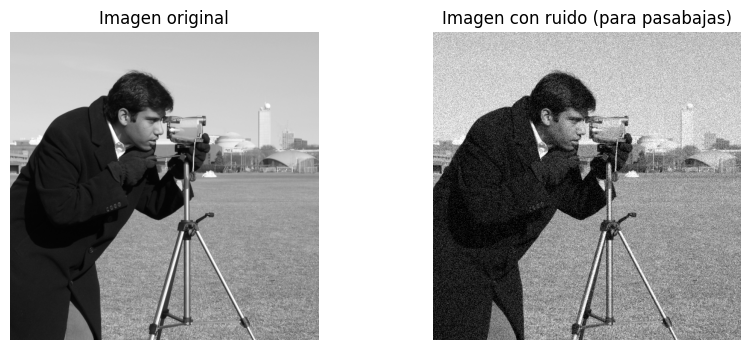

In [8]:
from skimage import data, util

# Imagen estándar de procesamiento digital de imágenes (512x512, escala de grises)
img = data.camera()

# Versión con ruido gaussiano para demostrar el mejoramiento con filtros pasabajas
rng = np.random.default_rng(42)
noise = rng.normal(0, 18, img.shape)
img_noisy = np.clip(img.astype(np.float64) + noise, 0, 255).astype(np.uint8)

print("Dimensiones:", img.shape)
print("Tipo:", img.dtype)

plt.figure(figsize=(10,4))
plt.subplot(1,2,1)
plt.imshow(img, cmap="gray")
plt.title("Imagen original")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(img_noisy, cmap="gray")
plt.title("Imagen con ruido (para pasabajas)")
plt.axis("off")
plt.show()


## Fast Fourier Transform (FFT) <a class="anchor" id="fft"></a>

La FFT calcula la transformada discreta de Fourier de la imagen. `fftshift` sitúa la frecuencia cero en el centro para facilitar la lectura; no modifica por sí solo el contenido de la imagen. Antes de aplicar `ifft2`, `ifftshift` devuelve las frecuencias a su disposición original.

**Figura 2:** original, espectro, espectro centrado, desplazamiento inverso y reconstrucción. Como aquí no se aplica ninguna máscara, la reconstrucción debe recuperar la original salvo errores numéricos. La escala logarítmica del espectro permite ver componentes débiles junto a las dominantes.


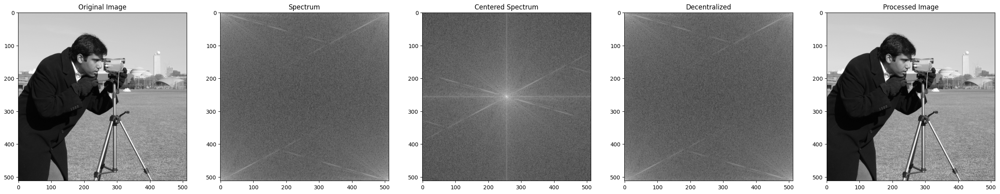

In [10]:
plt.figure(figsize=(6.4*5, 4.8*5), constrained_layout=False)

img = data.camera()
plt.subplot(151), plt.imshow(img, "gray"), plt.title("Original Image")

original = np.fft.fft2(img)
plt.subplot(152), plt.imshow(np.log(1+np.abs(original)), "gray"), plt.title("Spectrum")

center = np.fft.fftshift(original)
plt.subplot(153), plt.imshow(np.log(1+np.abs(center)), "gray"), plt.title("Centered Spectrum")

inv_center = np.fft.ifftshift(center)
plt.subplot(154), plt.imshow(np.log(1+np.abs(inv_center)), "gray"), plt.title("Decentralized")

processed_img = np.fft.ifft2(inv_center)
plt.subplot(155), plt.imshow(np.abs(processed_img), "gray"), plt.title("Processed Image")

plt.show()

### Magnitud y fase — Figura 3

La magnitud expresa cuánto contribuye cada frecuencia; la fase describe su alineación espacial y es importante para la estructura de la imagen. La figura muestra ambos componentes del espectro sin centrar. El logaritmo se usa solo para visualizar la magnitud; si existen magnitudes cero, `log(0)` puede producir valores no finitos.


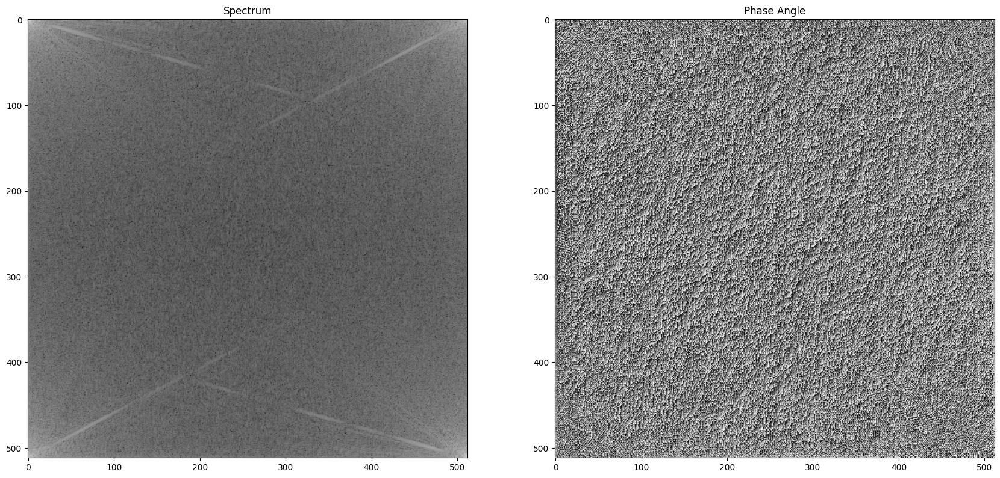

In [11]:
plt.figure(figsize=(6.4*5, 4.8*5), constrained_layout=False)

img = data.camera()

original = np.fft.fft2(img)
plt.subplot(131), plt.imshow(np.log(np.abs(original)), "gray"), plt.title("Spectrum")

plt.subplot(132), plt.imshow(np.angle(original), "gray"), plt.title("Phase Angle")
plt.show()

### Construcción de las seis máscaras

Las funciones siguientes calculan la distancia al centro del espectro y generan máscaras pasa-bajas o pasa-altas. No generan una figura por sí mismas.

- **Ideal:** conserva o rechaza según un umbral radial; su transición es abrupta.
- **Butterworth:** suaviza la transición mediante el orden `n`; valores altos aproximan el corte Ideal.
- **Gaussiano:** tiene un perfil de campana y una transición suave. Su pasa-altas es el complemento.

`D0` controla la escala radial, pero no tiene la misma interpretación exacta: el pasa-bajas Butterworth vale 0.5 en ese radio y el Gaussiano aproximadamente 0.607. Las máscaras están adaptadas a la imagen par de 512 × 512; cambiar a dimensiones impares requiere revisar el centro.


In [12]:
def distance(point1,point2):
    return sqrt((point1[0]-point2[0])**2 + (point1[1]-point2[1])**2)

def idealFilterLP(D0,imgShape):
    base = np.zeros(imgShape[:2])
    rows, cols = imgShape[:2]
    center = (rows/2,cols/2)
    for x in range(cols):
        for y in range(rows):
            if distance((y,x),center) < D0:
                base[y,x] = 1
    return base

def idealFilterHP(D0,imgShape):
    base = np.ones(imgShape[:2])
    rows, cols = imgShape[:2]
    center = (rows/2,cols/2)
    for x in range(cols):
        for y in range(rows):
            if distance((y,x),center) < D0:
                base[y,x] = 0
    return base

def butterworthLP(D0,imgShape,n):
    base = np.zeros(imgShape[:2])
    rows, cols = imgShape[:2]
    center = (rows/2,cols/2)
    for x in range(cols):
        for y in range(rows):
            base[y,x] = 1/(1+(distance((y,x),center)/D0)**(2*n))
    return base

def butterworthHP(D0,imgShape,n):
    base = np.zeros(imgShape[:2])
    rows, cols = imgShape[:2]
    center = (rows/2,cols/2)
    for x in range(cols):
        for y in range(rows):
            base[y,x] = 1-1/(1+(distance((y,x),center)/D0)**(2*n))
    return base

def gaussianLP(D0,imgShape):
    base = np.zeros(imgShape[:2])
    rows, cols = imgShape[:2]
    center = (rows/2,cols/2)
    for x in range(cols):
        for y in range(rows):
            base[y,x] = exp(((-distance((y,x),center)**2)/(2*(D0**2))))
    return base

def gaussianHP(D0,imgShape):
    base = np.zeros(imgShape[:2])
    rows, cols = imgShape[:2]
    center = (rows/2,cols/2)
    for x in range(cols):
        for y in range(rows):
            base[y,x] = 1 - exp(((-distance((y,x),center)**2)/(2*(D0**2))))
    return base

### Flujo completo con una máscara — Figura 4

El Ideal pasa-bajas con `D0=50` se multiplica por el espectro centrado. Se muestra cada etapa hasta reconstruir la imagen. Comparar con la figura 2: ahora sí se han retirado frecuencias, por lo que no se espera recuperar todos los detalles originales.


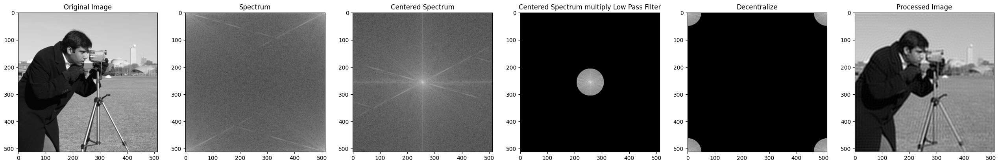

In [13]:
plt.figure(figsize=(6.4*5, 4.8*5), constrained_layout=False)

img = data.camera()
plt.subplot(161), plt.imshow(img, "gray"), plt.title("Original Image")

original = np.fft.fft2(img)
plt.subplot(162), plt.imshow(np.log(1+np.abs(original)), "gray"), plt.title("Spectrum")

center = np.fft.fftshift(original)
plt.subplot(163), plt.imshow(np.log(1+np.abs(center)), "gray"), plt.title("Centered Spectrum")

LowPassCenter = center * idealFilterLP(50,img.shape)
plt.subplot(164), plt.imshow(np.log(1+np.abs(LowPassCenter)), "gray"), plt.title("Centered Spectrum multiply Low Pass Filter")

LowPass = np.fft.ifftshift(LowPassCenter)
plt.subplot(165), plt.imshow(np.log(1+np.abs(LowPass)), "gray"), plt.title("Decentralize")

inverse_LowPass = np.fft.ifft2(LowPass)
plt.subplot(166), plt.imshow(np.abs(inverse_LowPass), "gray"), plt.title("Processed Image")

plt.show()

## Low Pass Filter <a class="anchor" id="low"></a>

Un pasa-bajas conserva variaciones suaves y atenúa cambios rápidos. Puede reducir ruido, pero también eliminar detalles. En este ejemplo se aplica un filtro Ideal con `D0=50` a la imagen limpia: demuestra suavizado, no todavía reducción de ruido medida.

**Figura 5:** espectro original, máscara, espectro filtrado, desplazamiento inverso y resultado. El centro blanco de la máscara indica las frecuencias conservadas. Un radio menor implica mayor suavizado.


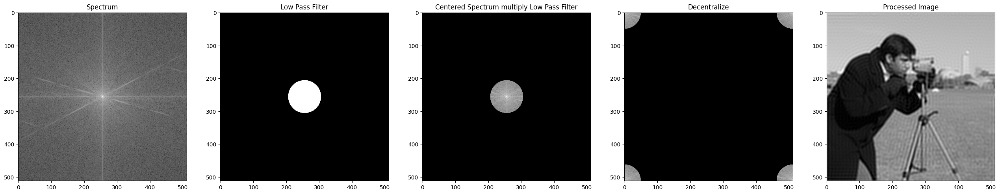

In [14]:
img = data.camera()
original = np.fft.fft2(img)
center = np.fft.fftshift(original)

plt.figure(figsize=(6.4*5, 4.8*5), constrained_layout=False)

plt.subplot(151), plt.imshow(np.log(1+np.abs(center)), "gray"), plt.title("Spectrum")

LowPass = idealFilterLP(50,img.shape)
plt.subplot(152), plt.imshow(np.abs(LowPass), "gray"), plt.title("Low Pass Filter")

LowPassCenter = center * idealFilterLP(50,img.shape)
plt.subplot(153), plt.imshow(np.log(1+np.abs(LowPassCenter)), "gray"), plt.title("Centered Spectrum multiply Low Pass Filter")

LowPass = np.fft.ifftshift(LowPassCenter)
plt.subplot(154), plt.imshow(np.log(1+np.abs(LowPass)), "gray"), plt.title("Decentralize")

inverse_LowPass = np.fft.ifft2(LowPass)
plt.subplot(155), plt.imshow(np.abs(inverse_LowPass), "gray"), plt.title("Processed Image")

plt.show()

## High Pass Filter <a class="anchor" id="high"></a>

Un pasa-altas atenúa variaciones lentas y conserva componentes asociadas a bordes, detalles y también ruido. Su máscara es el complemento de la pasa-bajas: `H_HP = 1 - H_LP`.

**Figura 6:** aplicación del Ideal con `D0=50`. Esta celda muestra `abs(inverse_HighPass)`: representa la magnitud de los detalles y pierde su signo. No debe confundirse con la imagen original mejorada. La aplicación final de realce sí conserva la respuesta con signo antes de sumarla a la original.


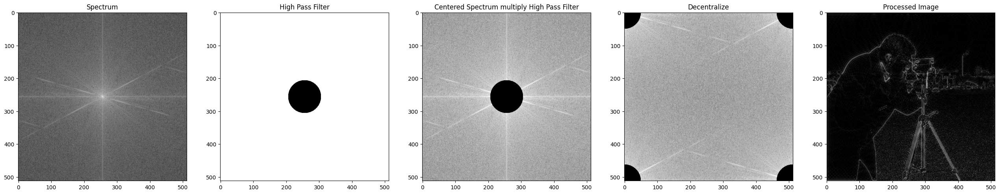

In [15]:
img = data.camera()
original = np.fft.fft2(img)
center = np.fft.fftshift(original)

plt.figure(figsize=(6.4*5, 4.8*5), constrained_layout=False)

plt.subplot(151), plt.imshow(np.log(1+np.abs(center)), "gray"), plt.title("Spectrum")

HighPass = idealFilterHP(50,img.shape)
plt.subplot(152), plt.imshow(np.abs(HighPass), "gray"), plt.title("High Pass Filter")

HighPassCenter = center * idealFilterHP(50,img.shape)
plt.subplot(153), plt.imshow(np.log(1+np.abs(HighPassCenter)), "gray"), plt.title("Centered Spectrum multiply High Pass Filter")

HighPass = np.fft.ifftshift(HighPassCenter)
plt.subplot(154), plt.imshow(np.log(1+np.abs(HighPass)), "gray"), plt.title("Decentralize")

inverse_HighPass = np.fft.ifft2(HighPass)
plt.subplot(155), plt.imshow(np.abs(inverse_HighPass), "gray"), plt.title("Processed Image")

plt.show()

### Máscaras Ideal — Figura 7

La región blanca pasa frecuencias y la negra las bloquea. Pasa-bajas y pasa-altas son complementarios; el borde abrupto puede producir ringing al filtrar una imagen.


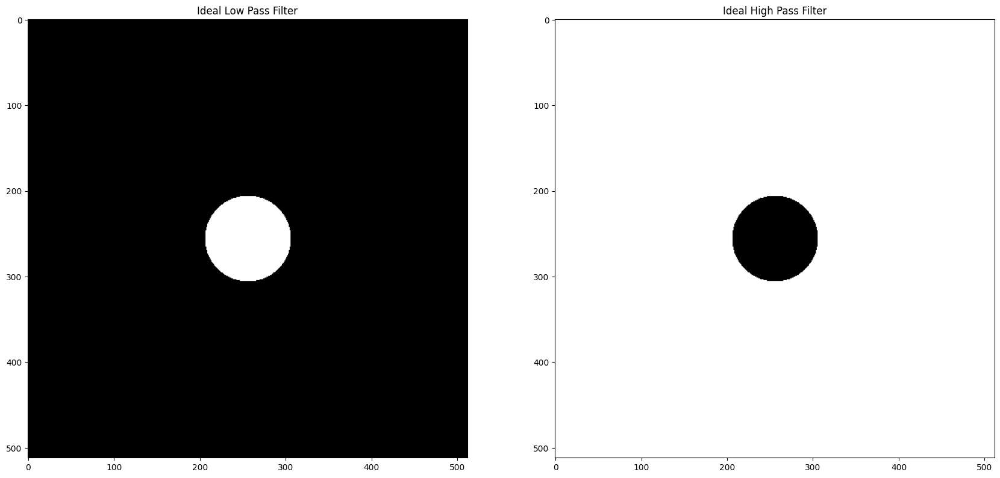

In [16]:
plt.figure(figsize=(6.4*5, 4.8*5), constrained_layout=False)

LowPass = idealFilterLP(50,img.shape)
plt.subplot(131), plt.imshow(LowPass, "gray"), plt.title("Ideal Low Pass Filter")

HighPass = idealFilterHP(50,img.shape)
plt.subplot(132), plt.imshow(HighPass, "gray"), plt.title("Ideal High Pass Filter")

plt.show()

### Butterworth de orden alto — Figura 8

Con `D0=50` y `n=20`, la transición es pronunciada y se aproxima a la Ideal. Una transición más abrupta puede aumentar las oscilaciones alrededor de los bordes.


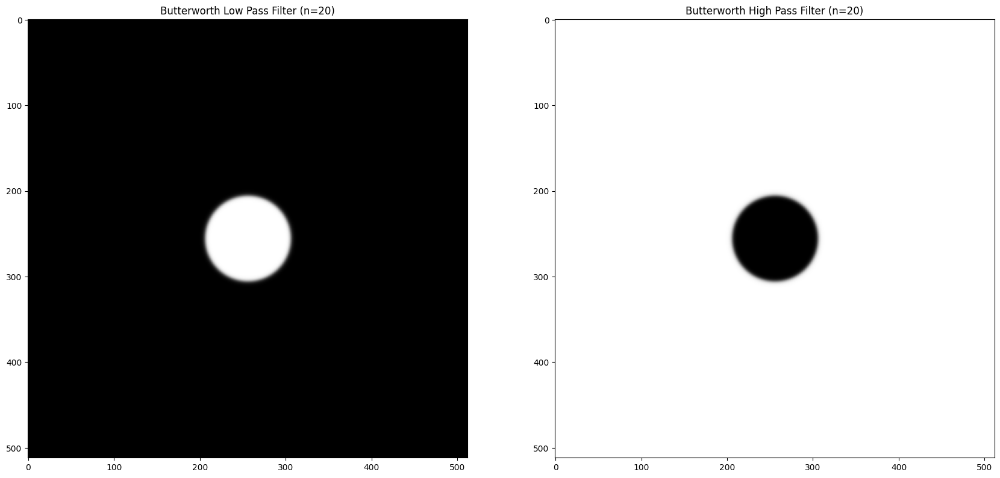

In [17]:
plt.figure(figsize=(6.4*5, 4.8*5), constrained_layout=False)

LowPass = butterworthLP(50,img.shape,20)
plt.subplot(131), plt.imshow(LowPass, "gray"), plt.title("Butterworth Low Pass Filter (n=20)")

HighPass = butterworthHP(50,img.shape,20)
plt.subplot(132), plt.imshow(HighPass, "gray"), plt.title("Butterworth High Pass Filter (n=20)")

plt.show()

### Butterworth de orden moderado — Figura 9

Se mantiene `D0=50` y se reduce el orden a `n=3`. Comparar la transición con la figura 8 permite aislar el efecto del orden, sin cambiar el radio.


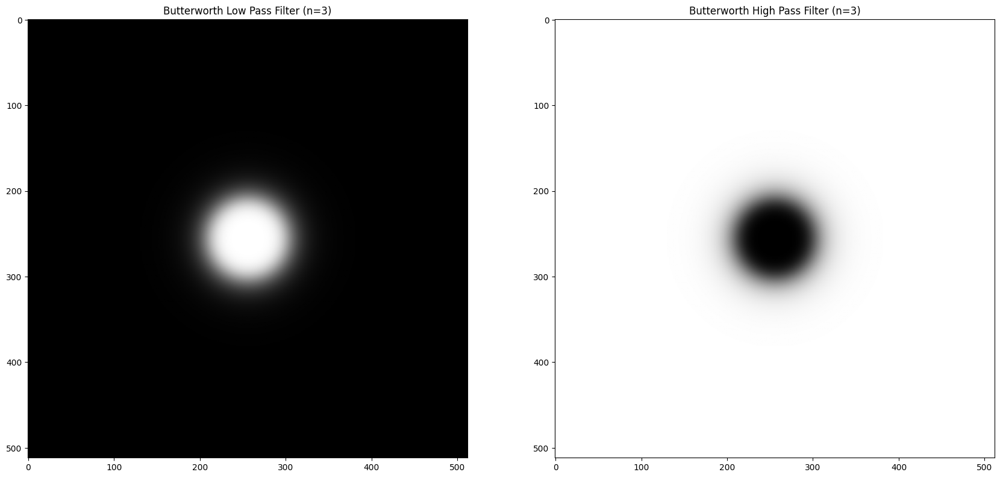

In [18]:
plt.figure(figsize=(6.4*5, 4.8*5), constrained_layout=False)

LowPass = butterworthLP(50,img.shape,3)
plt.subplot(131), plt.imshow(LowPass, "gray"), plt.title("Butterworth Low Pass Filter (n=3)")

HighPass = butterworthHP(50,img.shape,3)
plt.subplot(132), plt.imshow(HighPass, "gray"), plt.title("Butterworth High Pass Filter (n=3)")

plt.show()

### Máscaras Gaussianas — Figura 10

El pasa-bajas disminuye gradualmente desde el centro; su complemento pasa-altas aumenta hacia la periferia. La ausencia de corte abrupto evita el ringing característico del filtro Ideal. Esto no significa que conserve todos los detalles.


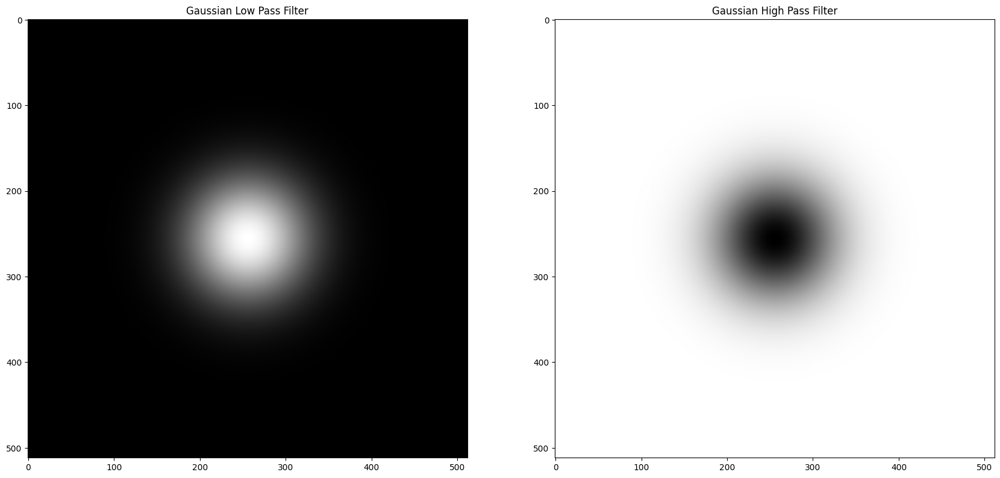

In [19]:
plt.figure(figsize=(6.4*5, 4.8*5), constrained_layout=False)

LowPass = gaussianLP(50,img.shape)
plt.subplot(131), plt.imshow(LowPass, "gray"), plt.title("Gaussian Low Pass Filter")

HighPass = gaussianHP(50,img.shape)
plt.subplot(132), plt.imshow(HighPass, "gray"), plt.title("Gaussian High Pass Filter")

plt.show()

### Comparación de familias — Figuras 11 y 12

La primera salida reúne las máscaras pasa-bajas y la segunda las pasa-altas. Se usa `D0=50` y Butterworth `n=10`. Observar la transición entre las regiones que pasan y las que atenúan frecuencias; estas figuras muestran máscaras, no imágenes filtradas.


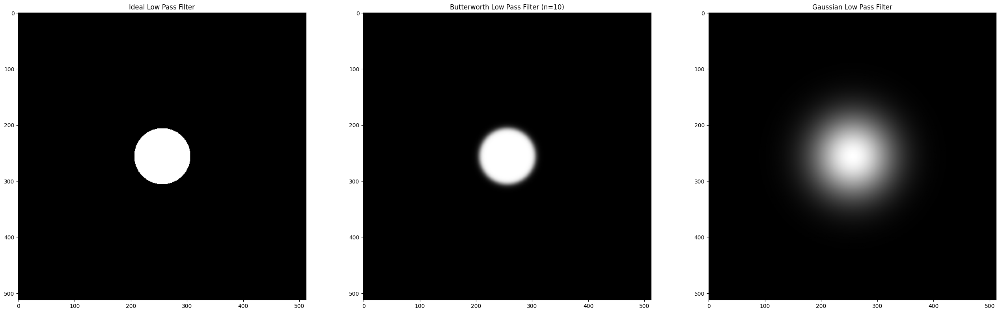

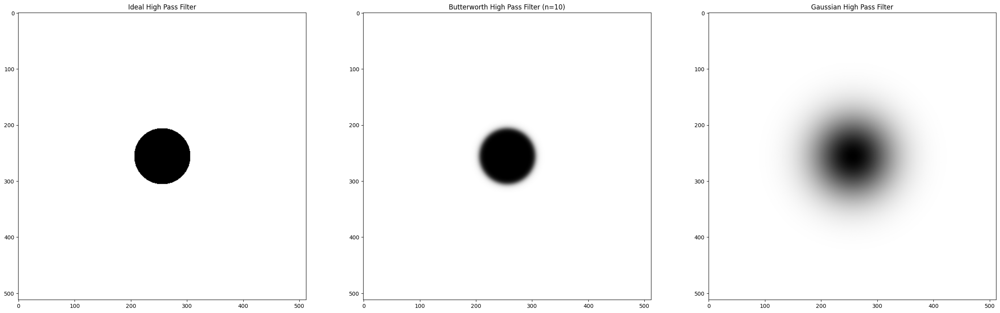

In [20]:
plt.figure(figsize=(6.4*5, 4.8*5), constrained_layout=False)

IdealLP = idealFilterLP(50,img.shape)
plt.subplot(131), plt.imshow(IdealLP, "gray"), plt.title("Ideal Low Pass Filter")

ButterLP = butterworthLP(50,img.shape,10)
plt.subplot(132), plt.imshow(ButterLP, "gray"), plt.title("Butterworth Low Pass Filter (n=10)")

GaussianLP = gaussianLP(50,img.shape)
plt.subplot(133), plt.imshow(GaussianLP, "gray"), plt.title("Gaussian Low Pass Filter")

plt.figure(figsize=(6.4*5, 4.8*5), constrained_layout=False)
IdealHP = idealFilterHP(50,img.shape)
plt.subplot(231), plt.imshow(IdealHP, "gray"), plt.title("Ideal High Pass Filter")

ButterHP = butterworthHP(50,img.shape,10)
plt.subplot(232), plt.imshow(ButterHP, "gray"), plt.title("Butterworth High Pass Filter (n=10)")

GaussianHP = gaussianHP(50,img.shape)
plt.subplot(233), plt.imshow(GaussianHP, "gray"), plt.title("Gaussian High Pass Filter")

plt.show()

### Efecto pasa-bajas sobre la imagen limpia — Figura 13

Se aplican las tres máscaras con `D0=50` y Butterworth `n=10`. Comparar suavizado, detalles finos y posibles oscilaciones. Esta celda visualiza valores absolutos con autoescala; la evaluación cuantitativa de reducción de ruido se realiza más adelante.


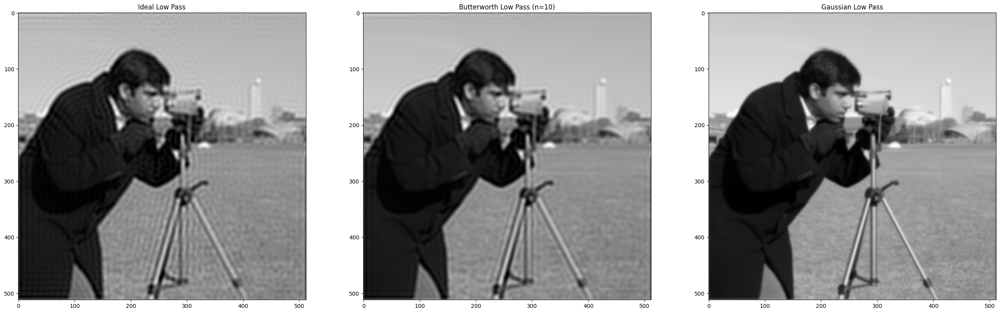

In [21]:
img = data.camera()
original = np.fft.fft2(img)
center = np.fft.fftshift(original)

plt.figure(figsize=(6.4*5, 4.8*5), constrained_layout=False)

LowPassCenter = center * idealFilterLP(50,img.shape)
LowPass = np.fft.ifftshift(LowPassCenter)
inverse_LowPass = np.fft.ifft2(LowPass)
plt.subplot(131), plt.imshow(np.abs(inverse_LowPass), "gray"), plt.title("Ideal Low Pass")

LowPassCenter = center * butterworthLP(50,img.shape,10)
LowPass = np.fft.ifftshift(LowPassCenter)
inverse_LowPass = np.fft.ifft2(LowPass)
plt.subplot(132), plt.imshow(np.abs(inverse_LowPass), "gray"), plt.title("Butterworth Low Pass (n=10)")

LowPassCenter = center * gaussianLP(50,img.shape)
LowPass = np.fft.ifftshift(LowPassCenter)
inverse_LowPass = np.fft.ifft2(LowPass)
plt.subplot(133), plt.imshow(np.abs(inverse_LowPass), "gray"), plt.title("Gaussian Low Pass")

plt.show()

### Componentes pasa-altas — Figura 14

Las respuestas muestran los detalles extraídos de `img`, cargada en la celda anterior. Aquí se usa valor absoluto y autoescala: las zonas brillantes indican magnitud, no valores positivos únicamente. La comparación no equivale todavía a sumar esos detalles a la original.


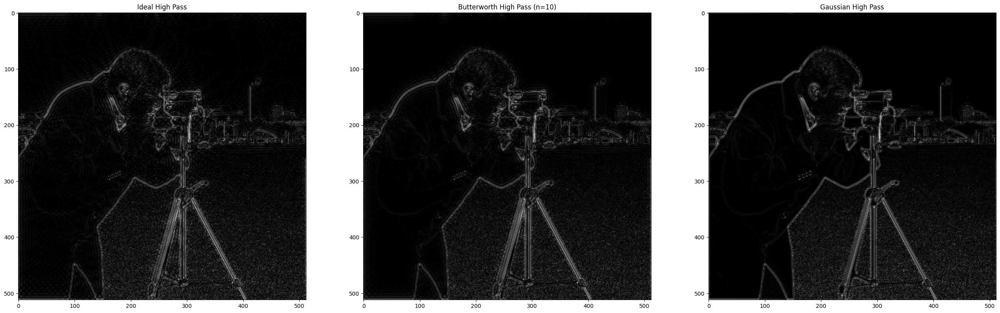

In [22]:
original = np.fft.fft2(img)
center = np.fft.fftshift(original)

plt.figure(figsize=(6.4*5, 4.8*5), constrained_layout=False)

HighPassCenter = center * idealFilterHP(50,img.shape)
HighPass = np.fft.ifftshift(HighPassCenter)
inverse_HighPass = np.fft.ifft2(HighPass)
plt.subplot(131), plt.imshow(np.abs(inverse_HighPass), "gray"), plt.title("Ideal High Pass")

HighPassCenter = center * butterworthHP(50,img.shape,10)
HighPass = np.fft.ifftshift(HighPassCenter)
inverse_HighPass = np.fft.ifft2(HighPass)
plt.subplot(132), plt.imshow(np.abs(inverse_HighPass), "gray"), plt.title("Butterworth High Pass (n=10)")

HighPassCenter = center * gaussianHP(50,img.shape)
HighPass = np.fft.ifftshift(HighPassCenter)
inverse_HighPass = np.fft.ifft2(HighPass)
plt.subplot(133), plt.imshow(np.abs(inverse_HighPass), "gray"), plt.title("Gaussian High Pass")

plt.show()

### Ejemplo Gaussiano completo — Figura 15

La original se compara con su versión pasa-bajas y la magnitud de su respuesta pasa-altas, usando `D0=50`. Es una síntesis del efecto complementario de ambas máscaras. El resultado pasa-altas no es todavía el realce final.


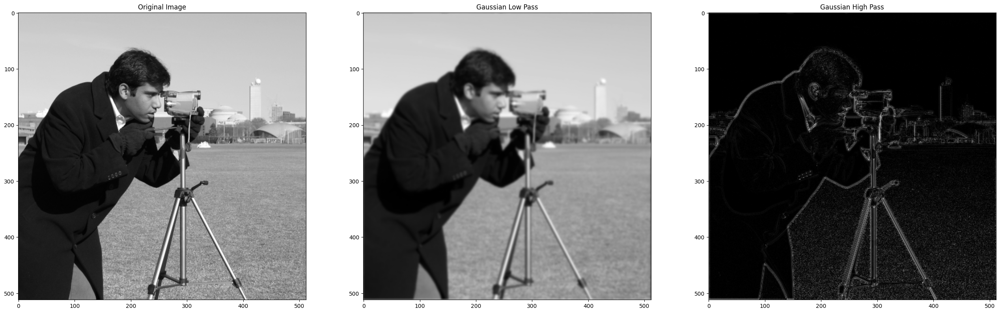

In [24]:
img = data.camera()
original = np.fft.fft2(img)
center = np.fft.fftshift(original)

plt.figure(figsize=(6.4*5, 4.8*5), constrained_layout=False)

plt.subplot(131), plt.imshow(img, "gray"), plt.title("Original Image")

LowPassCenter = center * gaussianLP(50,img.shape)
LowPass = np.fft.ifftshift(LowPassCenter)
inverse_LowPass = np.fft.ifft2(LowPass)
plt.subplot(132), plt.imshow(np.abs(inverse_LowPass), "gray"), plt.title("Gaussian Low Pass")

HighPassCenter = center * gaussianHP(50,img.shape)
HighPass = np.fft.ifftshift(HighPassCenter)
inverse_HighPass = np.fft.ifft2(HighPass)
plt.subplot(133), plt.imshow(np.abs(inverse_HighPass), "gray"), plt.title("Gaussian High Pass")

plt.show()

## a) Mejoramiento con pasa-bajas: reducción de ruido <a class="anchor" id="reduccion-ruido"></a>

La aplicación compara tres filtros sobre `img_noisy`, usando como referencia la imagen limpia `img`. Se fija `D0=45` y orden Butterworth `n=2`.

### Función genérica `apply_frequency_filter(image, mask)`

1. `fft2` obtiene el espectro de la imagen.
2. `fftshift` lo centra para alinearlo con la máscara.
3. La multiplicación elemento a elemento aplica `G = H * F`.
4. `ifftshift` deshace el centrado e `ifft2` reconstruye la imagen.
5. `np.real` conserva la parte real con signo, adecuada para las máscaras simétricas usadas aquí.

La función no valida entradas: requiere una imagen 2D y una máscara del mismo tamaño y con simetría compatible. No agrega padding; el filtrado supone periodicidad y puede mezclar información de bordes opuestos.

**Figura 16:** original, versión ruidosa y tres resultados. Los resultados se recortan a 0–255 y se convierten a `uint8` antes de visualizarlos y medirlos.

### Lectura de PSNR

PSNR compara cada resultado con la imagen limpia: un valor mayor indica menor error cuadrático, no necesariamente mejor calidad perceptual. Se usa `data_range=255`. El indicador requiere una referencia; no suele estar disponible en una imagen real cuyo original limpio se desconoce.


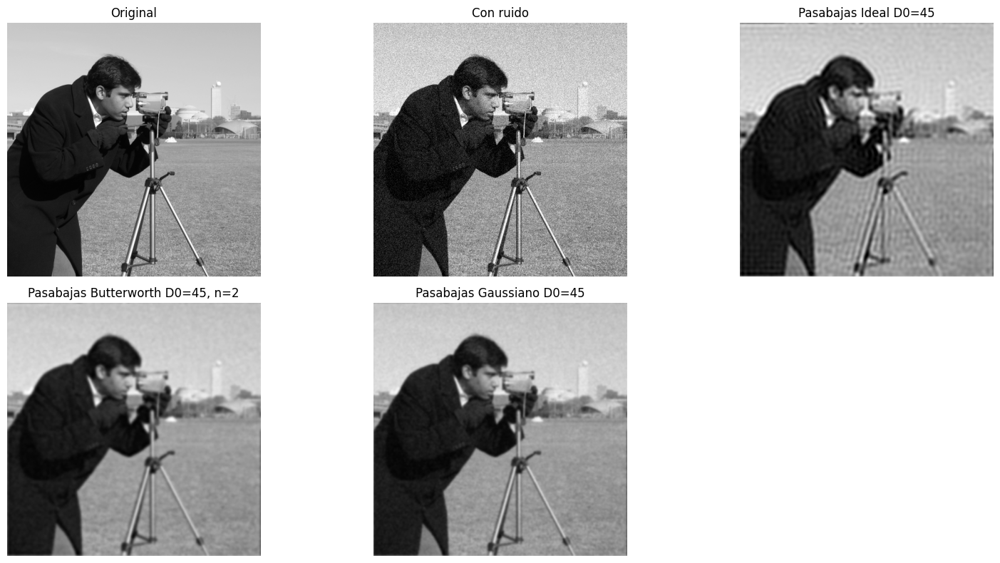

PSNR imagen con ruido:       23.27 dB
PSNR Ideal:                  24.13 dB
PSNR Butterworth:            25.12 dB
PSNR Gaussiano:              25.75 dB


In [25]:
from skimage.metrics import peak_signal_noise_ratio as psnr

def apply_frequency_filter(image, mask):
    F = np.fft.fft2(image)
    F_shift = np.fft.fftshift(F)
    G_shift = F_shift * mask
    G = np.fft.ifftshift(G_shift)
    result = np.real(np.fft.ifft2(G))
    return result

D0 = 45
n = 2

lp_ideal_mask = idealFilterLP(D0, img.shape)
lp_butter_mask = butterworthLP(D0, img.shape, n)
lp_gauss_mask = gaussianLP(D0, img.shape)

lp_ideal = apply_frequency_filter(img_noisy, lp_ideal_mask)
lp_butter = apply_frequency_filter(img_noisy, lp_butter_mask)
lp_gauss = apply_frequency_filter(img_noisy, lp_gauss_mask)

# Limitar a rango válido para visualización y métricas
lp_ideal_u8 = np.clip(lp_ideal, 0, 255).astype(np.uint8)
lp_butter_u8 = np.clip(lp_butter, 0, 255).astype(np.uint8)
lp_gauss_u8 = np.clip(lp_gauss, 0, 255).astype(np.uint8)

plt.figure(figsize=(16,8))
images = [img, img_noisy, lp_ideal_u8, lp_butter_u8, lp_gauss_u8]
titles = [
    'Original',
    'Con ruido',
    f'Pasabajas Ideal D0={D0}',
    f'Pasabajas Butterworth D0={D0}, n={n}',
    f'Pasabajas Gaussiano D0={D0}'
]
for i, (im, title) in enumerate(zip(images, titles), 1):
    plt.subplot(2,3,i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(title)
    plt.axis('off')
plt.tight_layout()
plt.show()

print('PSNR imagen con ruido:      ', round(psnr(img, img_noisy, data_range=255), 2), 'dB')
print('PSNR Ideal:                 ', round(psnr(img, lp_ideal_u8, data_range=255), 2), 'dB')
print('PSNR Butterworth:           ', round(psnr(img, lp_butter_u8, data_range=255), 2), 'dB')
print('PSNR Gaussiano:             ', round(psnr(img, lp_gauss_u8, data_range=255), 2), 'dB')


### Resultados guardados de reducción de ruido

| Imagen evaluada | PSNR |
|---|---:|
| Con ruido, sin filtrar | 23.27 dB |
| Pasa-bajas Ideal | 24.13 dB |
| Pasa-bajas Butterworth | 25.12 dB |
| Pasa-bajas Gaussiano | 25.75 dB |

Los tres filtros aumentan el PSNR en esta corrida. El Gaussiano alcanza el valor más alto entre los probados; esto no demuestra que siempre sea mejor ni que estos parámetros sean óptimos. La comparación corresponde a esta imagen, este ruido, estos parámetros y resultados recortados y cuantizados.

El Ideal puede producir ringing por su corte abrupto. Butterworth permite controlar la transición mediante `n`. El Gaussiano cambia suavemente, pero también puede borrar detalles. El ruido añadido tiene componentes en distintas frecuencias: el pasa-bajas no lo elimina por completo.


## b) Mejoramiento con pasa-altas: realce <a class="anchor" id="realce"></a>

Esta aplicación trabaja sobre la imagen limpia, no sobre la ruidosa. Se calculan tres respuestas pasa-altas con `D0=35` y orden Butterworth `n=2`. Después se usa:

`imagen_realzada = imagen_original + alpha * respuesta_pasa_altas`

Aquí `alpha=1.2` controla la intensidad del realce. Al conservar el signo se refuerzan diferencias locales; después se recorta a 0–255 y se convierte a `uint8`. El recorte puede saturar zonas claras u oscuras, por lo que un valor mayor de `alpha` no garantiza una mejora.

**Figura 17:** original y tres imágenes realzadas, todas con escala 0–255. Revisar contornos, texturas y posibles halos. A diferencia de las demostraciones iniciales, aquí se muestran imágenes completas realzadas y no solo la magnitud de sus altas frecuencias. No se calcula PSNR para esta aplicación.


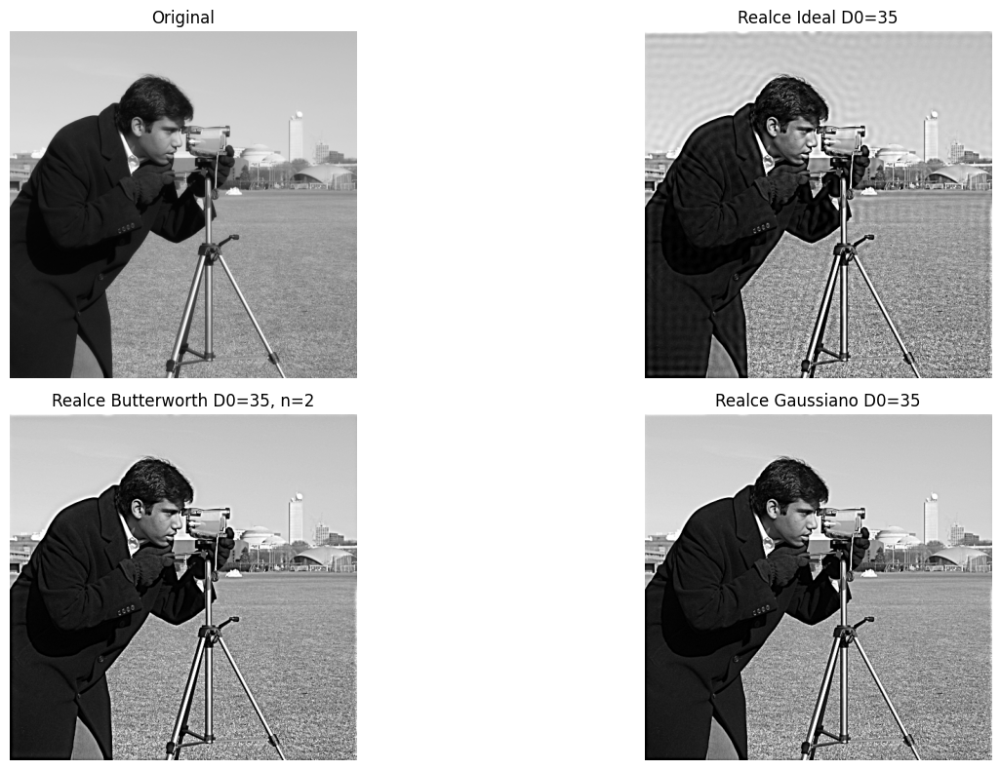

In [26]:
D0 = 35
n = 2
alpha = 1.2  # intensidad del realce

hp_ideal_mask = idealFilterHP(D0, img.shape)
hp_butter_mask = butterworthHP(D0, img.shape, n)
hp_gauss_mask = gaussianHP(D0, img.shape)

hp_ideal = apply_frequency_filter(img, hp_ideal_mask)
hp_butter = apply_frequency_filter(img, hp_butter_mask)
hp_gauss = apply_frequency_filter(img, hp_gauss_mask)

# Realce: original + alpha * componente de altas frecuencias
sharp_ideal = np.clip(img.astype(np.float64) + alpha * hp_ideal, 0, 255).astype(np.uint8)
sharp_butter = np.clip(img.astype(np.float64) + alpha * hp_butter, 0, 255).astype(np.uint8)
sharp_gauss = np.clip(img.astype(np.float64) + alpha * hp_gauss, 0, 255).astype(np.uint8)

plt.figure(figsize=(16,8))
images = [img, sharp_ideal, sharp_butter, sharp_gauss]
titles = [
    'Original',
    f'Realce Ideal D0={D0}',
    f'Realce Butterworth D0={D0}, n={n}',
    f'Realce Gaussiano D0={D0}'
]
for i, (im, title) in enumerate(zip(images, titles), 1):
    plt.subplot(2,2,i)
    plt.imshow(im, cmap='gray', vmin=0, vmax=255)
    plt.title(title)
    plt.axis('off')
plt.tight_layout()
plt.show()


## Conclusión y limitaciones <a class="anchor" id="conclusion"></a>

La práctica demuestra dos objetivos distintos: reducción de ruido con pasa-bajas y realce de detalles con pasa-altas. Ideal, Butterworth y Gaussiano permiten observar diferentes compromisos entre transición, suavizado, detalle y posibles artefactos.

La corrida guardada favorece al Gaussiano en PSNR para la reducción de ruido; no establece un ganador universal. Para el realce, se requiere valorar qué bordes importan y cuánto ruido, halo o saturación resulta aceptable. La decisión depende siempre del caso de estudio.

**Al interpretar las figuras:** las comparaciones iniciales usan autoescala de Matplotlib y algunas muestran valores absolutos. No permiten comparar directamente amplitudes entre resultados. Las aplicaciones finales fijan la escala 0–255. Todas usan máscaras sobre dimensiones pares; generalizar a dimensiones impares requiere revisar su centrado. La convolución sin padding es circular.

**Referencia:** Gonzalez, R. C., y Woods, R. E. *Digital Image Processing*, 4.ª edición, capítulo 4, especialmente secciones 4.7–4.9.
